# Dry bean classification: five-model comparison

This notebook is a runnable learning reference. The assignment permits AI for learning support, not direct copy-paste submissions. Understand and adapt the work yourself, disclose assistance as required, and perform your assignment on **BITS Virtual Lab**. Running this notebook here is not evidence of lab execution.

We use the [UCI Dry Bean dataset](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset): 13,611 published observations, 16 numeric features, and seven bean varieties. Source: Koklu, M. and Ozkan, I.A. (2020), *Multiclass classification of dry beans using computer vision and machine learning techniques*, Computers and Electronics in Agriculture, 174, 105507. Dataset DOI: [10.24432/C50S4B](https://doi.org/10.24432/C50S4B), CC BY 4.0.

Run the cells from top to bottom. The first run downloads the public workbook; later runs use the cached copy. Outputs are saved under `model/`, `results/`, and `test_data.csv`. The notebook does not create or deploy the separate Streamlit app.

## 1. Environment

Select a Python 3.11 kernel. Install dependencies from `requirements.txt` before running. The README contains Windows and Linux/macOS setup instructions.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
from importlib.metadata import version
import hashlib
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    matthews_corrcoef,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / 'data'
MODEL_DIR = PROJECT_ROOT / 'model'
RESULTS_DIR = PROJECT_ROOT / 'results'
for directory in (DATA_DIR, MODEL_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print('Python:', platform.python_version())
print('scikit-learn:', version('scikit-learn'))
print('Project folder:', PROJECT_ROOT)
print('Confirm this is the assignment folder before continuing.')

Python: 3.11.9
scikit-learn: 1.9.0
Project folder: C:\VP_Work\AI\AI_Tools\Assignments\MLAssignment2
Confirm this is the assignment folder before continuing.


## 2. Download and inspect the dataset

The source archive is downloaded over HTTPS from UCI. Only the expected workbook is read from the archive, and a SHA-256 digest is recorded for reproducibility. If the network is unavailable, download it manually from the UCI page and place `Dry_Bean_Dataset.xlsx` in `data/`.

Exact duplicate rows are removed **before** splitting. Identical feature vectors with conflicting labels cause an error rather than being silently assigned to different splits. No numeric imputation is needed for the published dataset; missing or nonfinite measurements are rejected.

Original shape: (13611, 17)
Exact duplicate rows removed: 68
Clean shape: (13543, 17)
Workbook SHA-256: a9efa69741c6c5d95167c962a13da23a456f7e940402a5add12639790e01f714


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000,13543.000
mean,53048.460,854.993,319.896,202.365,1.581,0.750,53767.987,253.034,0.750,0.987,0.874,0.800,0.007,0.002,0.644,0.995
std,29392.438,214.723,85.809,45.052,0.245,0.092,29844.249,59.308,0.049,0.005,0.059,0.061,0.001,0.001,0.099,0.004
min,20420.000,524.736,183.601,122.513,1.025,0.219,20684.000,161.244,0.555,0.919,0.490,0.641,0.003,0.001,0.410,0.948
25%,36282.500,703.230,253.087,175.886,1.431,0.715,36673.000,214.933,0.719,0.986,0.833,0.763,0.006,0.001,0.583,0.994
50%,44580.000,793.896,296.405,192.491,1.550,0.764,45122.000,238.246,0.760,0.988,0.883,0.802,0.007,0.002,0.642,0.996
75%,61382.000,977.146,376.312,217.245,1.704,0.810,62360.000,279.560,0.787,0.990,0.917,0.834,0.007,0.002,0.696,0.998
max,254616.000,1985.370,738.860,460.198,2.430,0.911,263261.000,569.374,0.866,0.995,0.991,0.987,0.010,0.004,0.975,1.000


,Instances
Class,
BARBUNYA,1322
BOMBAY,522
CALI,1630
DERMASON,3546
HOROZ,1860
SEKER,2027
SIRA,2636


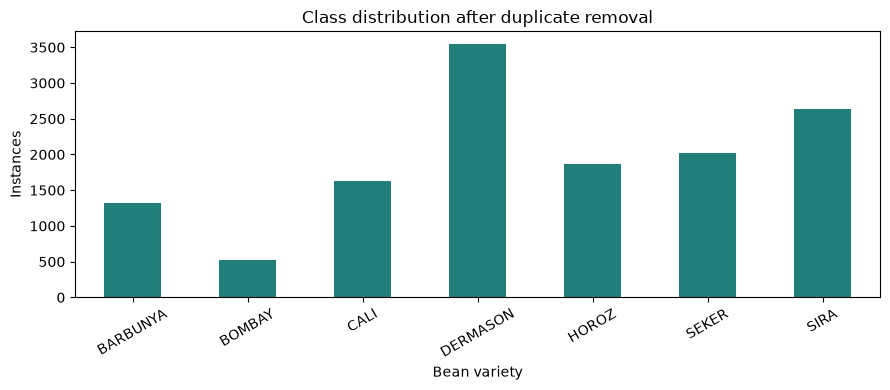

In [2]:
DATASET_URL = 'https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip'
WORKBOOK_PATH = DATA_DIR / 'Dry_Bean_Dataset.xlsx'
TARGET = 'Class'
FEATURES = [
    'Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation',
    'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity',
    'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
    'ShapeFactor3', 'ShapeFactor4',
]
EXPECTED_CLASSES = {'SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SIRA'}

if not WORKBOOK_PATH.exists():
    try:
        with urlopen(DATASET_URL, timeout=60) as response:
            archive_bytes = response.read()
        with ZipFile(BytesIO(archive_bytes)) as archive:
            workbook_names = [
                name for name in archive.namelist()
                if name.endswith('/Dry_Bean_Dataset.xlsx') or name == 'Dry_Bean_Dataset.xlsx'
            ]
            if len(workbook_names) != 1:
                raise ValueError('The archive does not contain exactly one expected workbook.')
            workbook_bytes = archive.read(workbook_names[0])
        pd.read_excel(BytesIO(workbook_bytes), engine='openpyxl', nrows=1)
        WORKBOOK_PATH.write_bytes(workbook_bytes)
    except Exception as error:
        raise RuntimeError(
            f'Dataset download failed. Download the workbook from UCI and place it at {WORKBOOK_PATH}.'
        ) from error

source_sha256 = hashlib.sha256(WORKBOOK_PATH.read_bytes()).hexdigest()
raw_data = pd.read_excel(WORKBOOK_PATH, engine='openpyxl')
if set(raw_data.columns) != set(FEATURES + [TARGET]):
    raise ValueError(f'Unexpected dataset columns: {raw_data.columns.tolist()}')
if raw_data[FEATURES + [TARGET]].isna().any().any():
    raise ValueError('Missing values found; review the data before proceeding.')
raw_data[FEATURES] = raw_data[FEATURES].apply(pd.to_numeric, errors='raise')
if not np.isfinite(raw_data[FEATURES].to_numpy(dtype=float)).all():
    raise ValueError('Nonfinite feature values found.')
if set(raw_data[TARGET].unique()) != EXPECTED_CLASSES:
    raise ValueError('The target labels do not match the seven expected bean varieties.')

clean_data = raw_data.drop_duplicates().reset_index(drop=True)
duplicate_count = len(raw_data) - len(clean_data)
if clean_data.duplicated(subset=FEATURES).any():
    raise ValueError('Identical feature vectors have conflicting labels. Review them before splitting.')
assert len(FEATURES) >= 12 and len(clean_data) >= 500

print(f'Original shape: {raw_data.shape}')
print(f'Exact duplicate rows removed: {duplicate_count}')
print(f'Clean shape: {clean_data.shape}')
print(f'Workbook SHA-256: {source_sha256}')
display(clean_data.head())
display(clean_data[FEATURES].describe().round(3))
class_counts = clean_data[TARGET].value_counts().sort_index()
display(class_counts.rename('Instances').to_frame())
figure, axis = plt.subplots(figsize=(9, 4))
class_counts.plot.bar(ax=axis, color='#207f79')
axis.set(title='Class distribution after duplicate removal', xlabel='Bean variety', ylabel='Instances')
axis.tick_params(axis='x', rotation=30)
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'class_distribution.png', dpi=150)
plt.show()

## 3. Shared split and model definitions

Reserve 20% of the cleaned data for a stratified test set. Use three-fold stratified cross-validation on the remaining training data to compare fixed, modest baseline configurations. Select a model by mean validation macro F1 **before** inspecting the test scores; ties use model-name order. These settings are baselines, not a claim of optimal tuning.

Scaling is fitted inside each pipeline and each cross-validation fold. Logistic regression uses an L2-regularized linear boundary; the decision tree has depth and leaf-size limits; KNN uses seven distance-weighted neighbours; Gaussian Naive Bayes models continuous features; and SVM uses an RBF kernel. SVM probability estimates are enabled for multiclass AUC. Gaussian Naive Bayes is also scaled to keep numerical variance smoothing comparable across features.

In [3]:
train_rows, test_rows = train_test_split(
    clean_data.index.to_numpy(), test_size=TEST_SIZE,
    stratify=clean_data[TARGET], random_state=RANDOM_STATE,
)
train_data = clean_data.loc[train_rows].copy()
test_data = clean_data.loc[test_rows].copy()
train_features = train_data[FEATURES]
train_target = train_data[TARGET]
test_features = test_data[FEATURES]
test_target = test_data[TARGET]
assert set(train_rows).isdisjoint(test_rows)
assert not pd.concat([train_features, test_features]).duplicated().any()
assert set(train_target.unique()) == set(test_target.unique()) == EXPECTED_CLASSES

test_data.to_csv(PROJECT_ROOT / 'test_data.csv', index=False)
split_counts = pd.DataFrame({
    'Train': train_target.value_counts(),
    'Test': test_target.value_counts(),
}).sort_index()
print(f'Train: {len(train_data):,}; test: {len(test_data):,}')
display(split_counts)

model_specs = {
    'Logistic Regression': {
        'filename': 'logistic_regression.joblib',
        'scale': True,
        'estimator': LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
    },
    'Decision Tree': {
        'filename': 'decision_tree.joblib',
        'scale': False,
        'estimator': DecisionTreeClassifier(max_depth=10, min_samples_leaf=3, random_state=RANDOM_STATE),
    },
    'KNN': {
        'filename': 'knn.joblib',
        'scale': True,
        'estimator': KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=1),
    },
    'Naive Bayes': {
        'filename': 'naive_bayes.joblib',
        'scale': True,
        'estimator': GaussianNB(),
    },
    'Support Vector Machine': {
        'filename': 'support_vector_machine.joblib',
        'scale': True,
        'estimator': SVC(C=10.0, kernel='rbf', gamma='scale', probability=True, random_state=RANDOM_STATE),
    },
}
model_templates = {}
for model_name, specification in model_specs.items():
    steps = []
    if specification['scale']:
        steps.append(('scaler', StandardScaler()))
    steps.append(('classifier', specification['estimator']))
    model_templates[model_name] = Pipeline(steps)

validation_split = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
validation_rows = []
for model_name, pipeline in model_templates.items():
    print(f'Cross-validating {model_name}...', flush=True)
    scores = cross_validate(
        pipeline, train_features, train_target, cv=validation_split,
        scoring={'macro_f1': 'f1_macro', 'accuracy': 'accuracy'},
        return_train_score=True, n_jobs=1, error_score='raise',
    )
    validation_rows.append({
        'ML Model Name': model_name,
        'Train F1': scores['train_macro_f1'].mean(),
        'Validation F1': scores['test_macro_f1'].mean(),
        'Validation F1 Std': scores['test_macro_f1'].std(),
        'Validation Accuracy': scores['test_accuracy'].mean(),
    })
validation_results = pd.DataFrame(validation_rows).set_index('ML Model Name')
selected_model = validation_results.reset_index().sort_values(
    ['Validation F1', 'ML Model Name'], ascending=[False, True],
).iloc[0]['ML Model Name']
validation_results.to_csv(RESULTS_DIR / 'cross_validation.csv')
display(validation_results.round(4))
print('Selected using training-only validation:', selected_model)

Train: 10,834; test: 2,709


,Train,Test
Class,,
BARBUNYA,1057,265
BOMBAY,418,104
CALI,1304,326
DERMASON,2837,709
HOROZ,1488,372
SEKER,1621,406
SIRA,2109,527


Cross-validating Logistic Regression...


Cross-validating Decision Tree...


Cross-validating KNN...


Cross-validating Naive Bayes...


... (2 outputs left out)

C:\Users\jayantibhai\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\jayantibhai\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Train F1,Validation F1,Validation F1 Std,Validation Accuracy
ML Model Name,,,,
Logistic Regression,0.9385,0.9365,0.0015,0.9244
Decision Tree,0.9653,0.9202,0.0022,0.9064
KNN,1.0000,0.9356,0.0000,0.9225
Naive Bayes,0.9062,0.9068,0.0064,0.8970
Support Vector Machine,0.9514,0.9431,0.0028,0.9319


Selected using training-only validation: Support Vector Machine


## 4. Evaluation and final fitting

Accuracy and MCC use predicted labels. Precision, recall, and F1 use macro averaging over the complete trained class list, with `zero_division=0`. AUC uses probability scores with macro one-vs-rest averaging and the fitted class order. AUC is shown as missing (`NaN` / `N/A`) when test data omits a trained class, because full-class AUC is then undefined.

The evaluation function below only validates data and predicts; it never fits a model. Training occurs separately. scikit-learn 1.9 emits a future-deprecation warning for `SVC(probability=True)`; the tested version is pinned in the requirements. Before upgrading to 1.11, migrate to probability calibration and retrain the artifacts.

In [4]:
def evaluate_model(fitted_pipeline, labelled_data):
    if not isinstance(labelled_data, pd.DataFrame) or labelled_data.empty:
        raise ValueError('Provide a nonempty labelled dataframe.')
    if labelled_data.columns.duplicated().any():
        raise ValueError('Duplicate column names are not allowed.')
    feature_names = fitted_pipeline.feature_names_in_.tolist()
    expected_columns = feature_names + [TARGET]
    missing_columns = sorted(set(expected_columns) - set(labelled_data.columns))
    extra_columns = sorted(set(labelled_data.columns) - set(expected_columns))
    if missing_columns or extra_columns:
        raise ValueError(f'Missing columns: {missing_columns}; unexpected columns: {extra_columns}')
    if labelled_data[expected_columns].isna().any().any():
        raise ValueError('Missing features or target labels are not allowed.')
    features = labelled_data[feature_names].apply(pd.to_numeric, errors='raise')
    if not np.isfinite(features.to_numpy(dtype=float)).all():
        raise ValueError('All feature values must be finite numbers.')
    target = labelled_data[TARGET]
    class_names = fitted_pipeline.classes_
    if not target.isin(class_names).all():
        raise ValueError('The target contains labels not seen during training.')

    predictions = fitted_pipeline.predict(features)
    probabilities = fitted_pipeline.predict_proba(features)
    precision, recall, f1_score, _ = precision_recall_fscore_support(
        target, predictions, labels=class_names, average='macro', zero_division=0,
    )
    auc_note = ''
    auc_score = np.nan
    if set(target.unique()) == set(class_names):
        auc_score = roc_auc_score(
            target, probabilities, labels=class_names, multi_class='ovr', average='macro',
        )
    else:
        auc_note = 'AUC is unavailable because the test data does not contain every trained class.'
    metrics = {
        'Accuracy': accuracy_score(target, predictions),
        'AUC': auc_score,
        'Precision': precision,
        'Recall': recall,
        'F1': f1_score,
        'MCC': matthews_corrcoef(target, predictions),
    }
    report = classification_report(
        target, predictions, labels=class_names, target_names=class_names.tolist(),
        output_dict=True, zero_division=0,
    )
    return metrics, predictions, report, auc_note


fitted_models = {}
predictions_by_model = {}
reports_by_model = {}
metric_rows = []
fit_times = {}
for model_name, template in model_templates.items():
    print(f'Fitting {model_name}...', flush=True)
    started_at = time.perf_counter()
    fitted_pipeline = clone(template).fit(train_features, train_target)
    fit_times[model_name] = time.perf_counter() - started_at
    metrics, predictions, report, auc_note = evaluate_model(fitted_pipeline, test_data)
    assert not auc_note
    fitted_models[model_name] = fitted_pipeline
    predictions_by_model[model_name] = predictions
    reports_by_model[model_name] = report
    metric_rows.append({'ML Model Name': model_name, **metrics})
    joblib.dump(fitted_pipeline, MODEL_DIR / model_specs[model_name]['filename'])

comparison = pd.DataFrame(metric_rows).set_index('ML Model Name')
comparison.to_csv(RESULTS_DIR / 'metrics.csv')
assert comparison.shape == (5, 6)
assert np.isfinite(comparison.to_numpy()).all()
assert comparison.drop(columns='MCC').ge(0).all().all()
assert comparison.drop(columns='MCC').le(1).all().all()
assert comparison['MCC'].between(-1, 1).all()
display(comparison.round(4))
print('Model selected before test evaluation:', selected_model)

Fitting Logistic Regression...


Fitting Decision Tree...


Fitting KNN...


Fitting Naive Bayes...


Fitting Support Vector Machine...


C:\Users\jayantibhai\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9192,0.9947,0.9307,0.9300,0.9302,0.9023
Decision Tree,0.9022,0.9747,0.9167,0.9169,0.9166,0.8818
KNN,0.9136,0.9854,0.9268,0.9237,0.9250,0.8956
Naive Bayes,0.8970,0.9911,0.9081,0.9082,0.9072,0.8762
Support Vector Machine,0.9236,0.9944,0.9356,0.9340,0.9347,0.9076


Model selected before test evaluation: Support Vector Machine


## 5. Class-level errors and observations

Each confusion matrix uses the same class order. Read its rows as true classes and columns as predictions. The per-class reports help identify whether a high aggregate score hides poor performance on a smaller class.

The observation table combines measured scores with the models' assumptions. Cross-validation train scores are in-sample diagnostics, not generalization estimates. In particular, distance-weighted KNN can achieve a perfect training score because a training point is its own nearest neighbour.

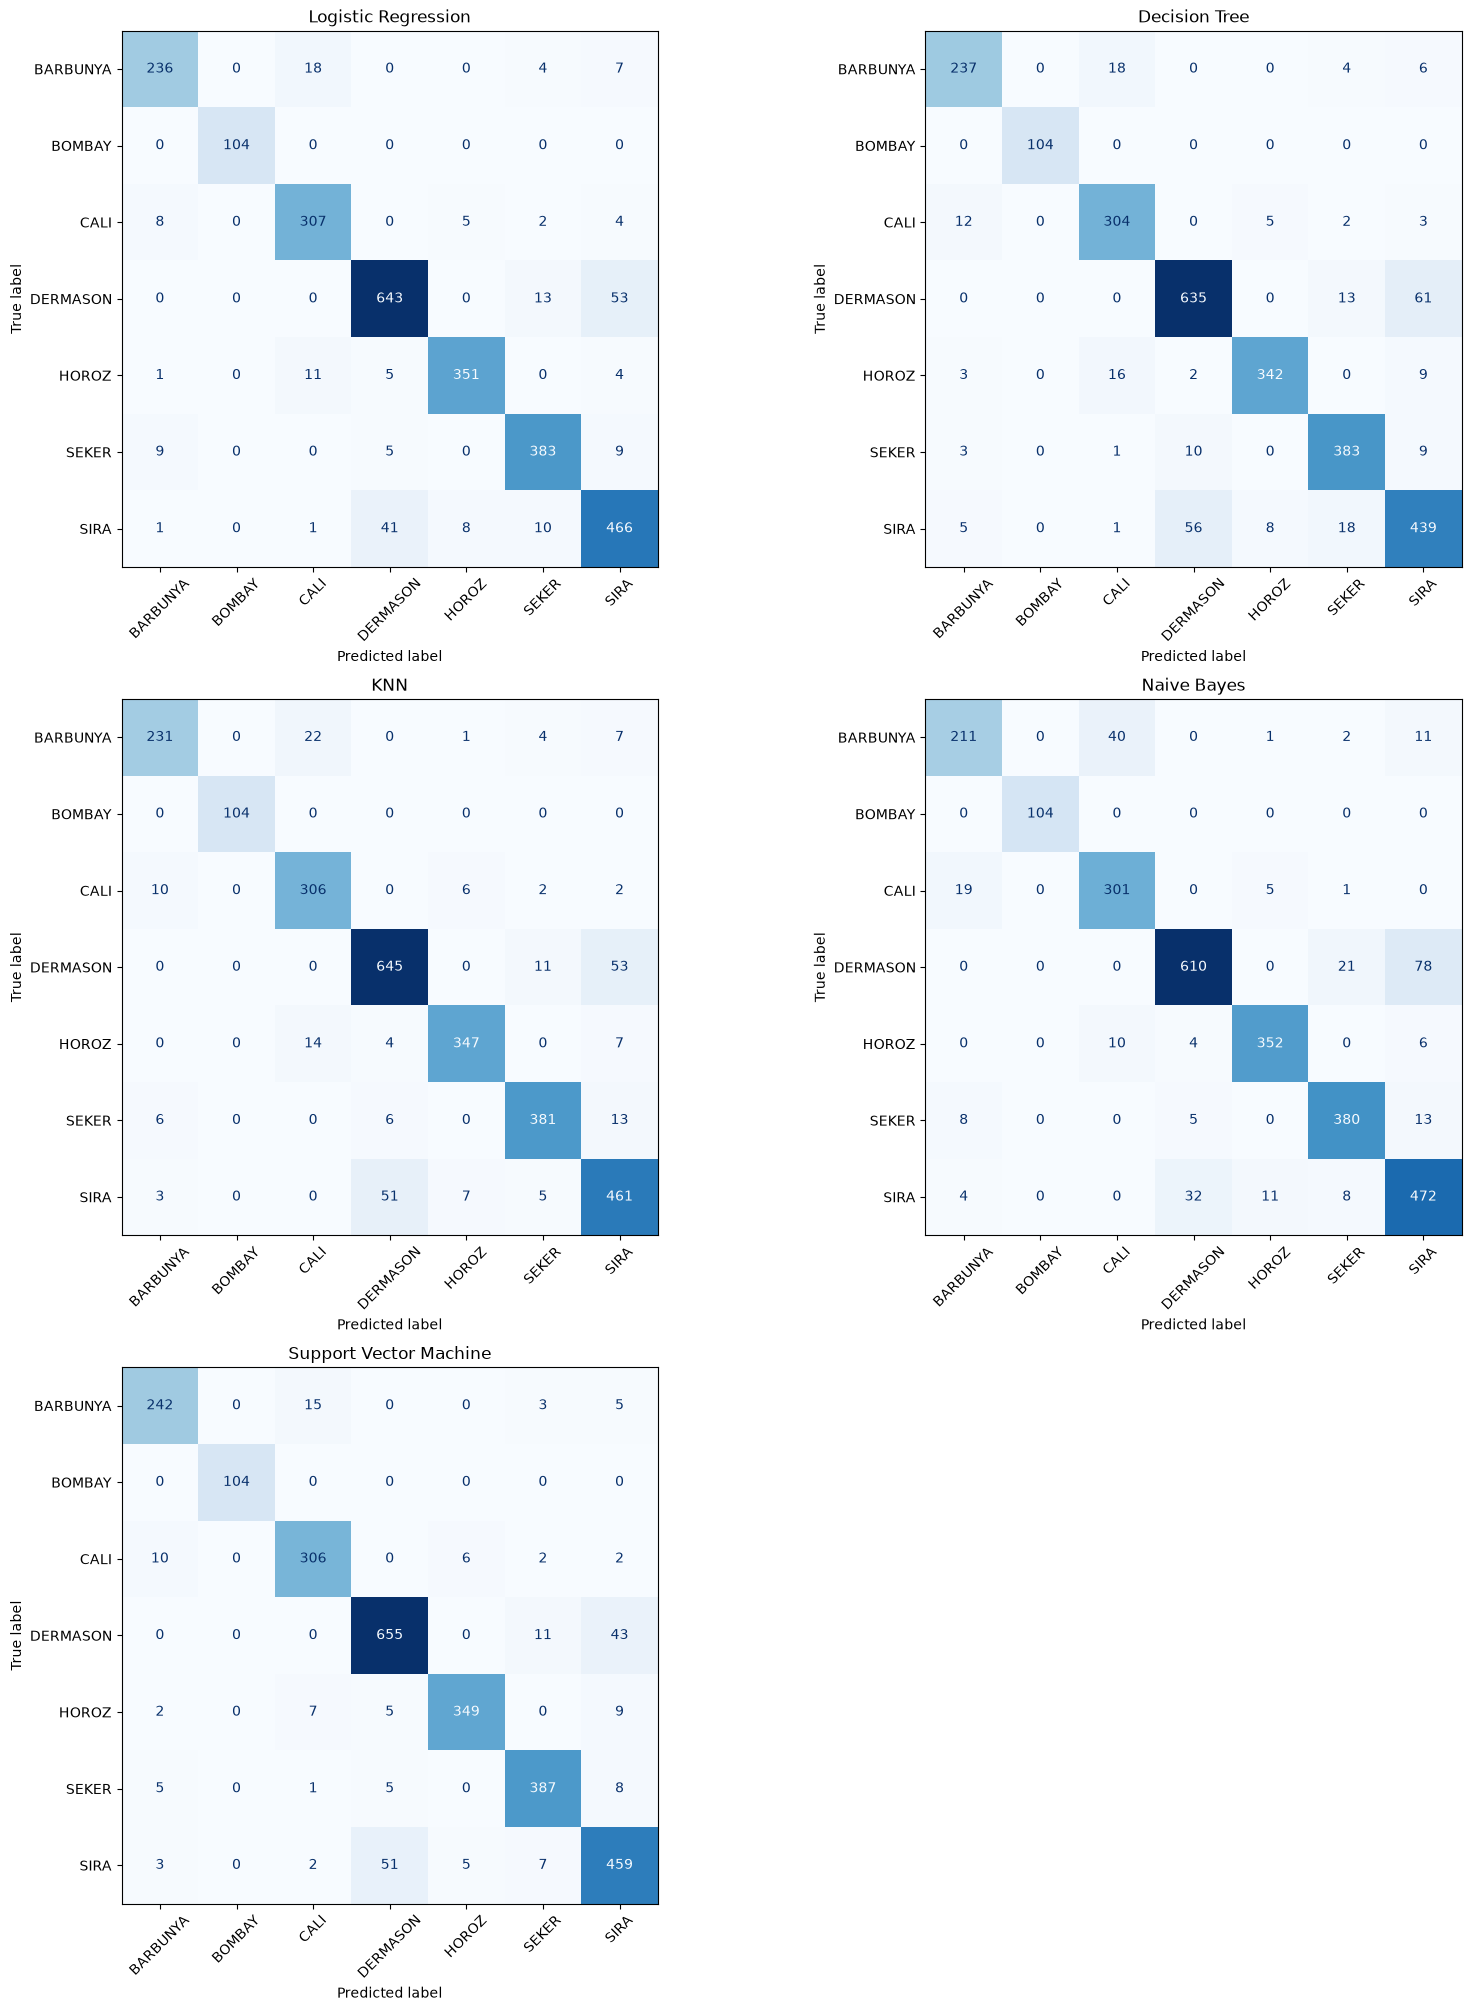

Classification report for the model selected by cross-validation:


,precision,recall,f1-score,support
BARBUNYA,0.9237,0.9132,0.9184,265.0000
BOMBAY,1.0000,1.0000,1.0000,104.0000
CALI,0.9245,0.9387,0.9315,326.0000
DERMASON,0.9148,0.9238,0.9193,709.0000
HOROZ,0.9694,0.9382,0.9536,372.0000
SEKER,0.9439,0.9532,0.9485,406.0000
SIRA,0.8726,0.8710,0.8718,527.0000
accuracy,0.9236,0.9236,0.9236,0.9236
macro avg,0.9356,0.9340,0.9347,2709.0000
weighted avg,0.9238,0.9236,0.9236,2709.0000


,ML Model Name,Observation
0,Logistic Regression,"Test accuracy 0.9192, macro F1 0.9302, AUC 0.9947; CV train-validation F1 gap 0.0020. A scaled linear baseline. Compare its AUC with F1: probability ranking and final class decisions measure different things."
1,Decision Tree,"Test accuracy 0.9022, macro F1 0.9166, AUC 0.9747; CV train-validation F1 gap 0.0451. The train-validation F1 gap is evidence to consider when assessing overfitting despite the depth and leaf-size limits."
2,KNN,"Test accuracy 0.9136, macro F1 0.9250, AUC 0.9854; CV train-validation F1 gap 0.0644. Distance-weighted neighbours need scaling. Its perfect in-sample score is expected from self-neighbours and does not imply perfect generalization."
3,Naive Bayes,"Test accuracy 0.8970, macro F1 0.9072, AUC 0.9911; CV train-validation F1 gap -0.0007. The independent Gaussian feature assumption is restrictive for related shape measurements; the scores alone do not prove the cause of errors."
4,Support Vector Machine,"Test accuracy 0.9236, macro F1 0.9347, AUC 0.9944; CV train-validation F1 gap 0.0083. The scaled RBF model allows nonlinear boundaries. Compare the validation result with held-out F1 rather than selecting parameters on the test set."


Validation-selected model: Support Vector Machine
Highest observed test macro F1: Support Vector Machine (0.9347)
This is one fixed split, not a statistical claim that the winner is always superior.


In [5]:
figure, axes = plt.subplots(3, 2, figsize=(16, 20), layout='constrained')
for axis, (model_name, fitted_pipeline) in zip(axes.flat, fitted_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        test_target, predictions_by_model[model_name], labels=fitted_pipeline.classes_,
        display_labels=fitted_pipeline.classes_, cmap='Blues', colorbar=False,
        xticks_rotation=45, ax=axis,
    )
    axis.set_title(model_name)
    report_frame = pd.DataFrame(reports_by_model[model_name]).transpose()
    report_stem = Path(model_specs[model_name]['filename']).stem
    report_frame.to_csv(RESULTS_DIR / f'{report_stem}_classification_report.csv')
axes.flat[-1].set_visible(False)
figure.savefig(RESULTS_DIR / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

print('Classification report for the model selected by cross-validation:')
display(pd.DataFrame(reports_by_model[selected_model]).transpose().round(4))
model_notes = {
    'Logistic Regression': 'A scaled linear baseline. Compare its AUC with F1: probability ranking and final class decisions measure different things.',
    'Decision Tree': 'The train-validation F1 gap is evidence to consider when assessing overfitting despite the depth and leaf-size limits.',
    'KNN': 'Distance-weighted neighbours need scaling. Its perfect in-sample score is expected from self-neighbours and does not imply perfect generalization.',
    'Naive Bayes': 'The independent Gaussian feature assumption is restrictive for related shape measurements; the scores alone do not prove the cause of errors.',
    'Support Vector Machine': 'The scaled RBF model allows nonlinear boundaries. Compare the validation result with held-out F1 rather than selecting parameters on the test set.',
}
observation_rows = []
for model_name in comparison.index:
    scores = comparison.loc[model_name]
    validation_gap = validation_results.loc[model_name, 'Train F1'] - validation_results.loc[model_name, 'Validation F1']
    observation_rows.append({
        'ML Model Name': model_name,
        'Observation': (
            f'Test accuracy {scores["Accuracy"]:.4f}, macro F1 {scores["F1"]:.4f}, '
            f'AUC {scores["AUC"]:.4f}; CV train-validation F1 gap {validation_gap:.4f}. '
            + model_notes[model_name]
        ),
    })
observations = pd.DataFrame(observation_rows)
observations.to_csv(RESULTS_DIR / 'observations.csv', index=False)
with pd.option_context('display.max_colwidth', None):
    display(observations)

best_test_model = comparison['F1'].idxmax()
print(f'Validation-selected model: {selected_model}')
print(f'Highest observed test macro F1: {best_test_model} ({comparison.loc[best_test_model, "F1"]:.4f})')
print('This is one fixed split, not a statistical claim that the winner is always superior.')

## 6. Reproducibility and focused checks

Save the dataset digest, exact split indices, feature/class schema, fitted estimator settings, and runtime versions. Reload every pipeline and check that its predictions and probabilities agree with the in-memory model. Then check CSV round-tripping, reordered columns, missing-class AUC, and invalid input rejection.

Only load model artifacts you trust. Joblib uses pickle-based serialization, which can execute code when loading an untrusted file.

In [6]:
package_names = ['numpy', 'pandas', 'scikit-learn', 'scipy', 'matplotlib', 'joblib', 'openpyxl', 'ipykernel']
package_versions = {package: version(package) for package in package_names}
metadata = {
    'dataset_url': DATASET_URL,
    'dataset_sha256': source_sha256,
    'original_rows': len(raw_data),
    'duplicates_removed': duplicate_count,
    'clean_rows': len(clean_data),
    'features': FEATURES,
    'target': TARGET,
    'classes': fitted_models[selected_model].classes_.tolist(),
    'random_state': RANDOM_STATE,
    'test_size': TEST_SIZE,
    'train_rows': len(train_data),
    'test_rows': len(test_data),
    'train_indices': train_rows.tolist(),
    'test_indices': test_rows.tolist(),
    'selection_criterion': 'Mean three-fold stratified training-only cross-validation macro F1',
    'selected_model': selected_model,
    'python_version': platform.python_version(),
    'packages': package_versions,
    'metric_convention': 'Macro precision/recall/F1; macro one-vs-rest AUC; multiclass MCC',
    'models': {
        model_name: {
            'filename': model_specs[model_name]['filename'],
            'scaled': model_specs[model_name]['scale'],
            'parameters': pipeline.named_steps['classifier'].get_params(),
            'fit_seconds': fit_times[model_name],
        }
        for model_name, pipeline in fitted_models.items()
    },
}
(MODEL_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2, allow_nan=False), encoding='utf-8')
(RESULTS_DIR / 'environment.json').write_text(
    json.dumps({'python': platform.python_version(), 'packages': package_versions}, indent=2),
    encoding='utf-8',
)

csv_test_data = pd.read_csv(PROJECT_ROOT / 'test_data.csv', float_precision='round_trip')
for model_name, original_pipeline in fitted_models.items():
    loaded_pipeline = joblib.load(MODEL_DIR / model_specs[model_name]['filename'])
    np.testing.assert_array_equal(loaded_pipeline.predict(test_features), predictions_by_model[model_name])
    np.testing.assert_allclose(
        loaded_pipeline.predict_proba(test_features), original_pipeline.predict_proba(test_features),
        rtol=0, atol=1e-12,
    )
    csv_metrics, _, _, _ = evaluate_model(loaded_pipeline, csv_test_data)
    np.testing.assert_allclose(
        list(csv_metrics.values()), comparison.loc[model_name].to_numpy(), rtol=0, atol=1e-12,
    )

probe_pipeline = fitted_models['Logistic Regression']
reordered_metrics, _, _, _ = evaluate_model(probe_pipeline, test_data[test_data.columns[::-1]])
np.testing.assert_allclose(list(reordered_metrics.values()), comparison.loc['Logistic Regression'].to_numpy())
one_class_data = test_data.loc[test_data[TARGET] == 'SIRA']
partial_metrics, _, _, partial_note = evaluate_model(probe_pipeline, one_class_data)
assert np.isnan(partial_metrics['AUC']) and partial_note
assert all(np.isfinite(value) for metric, value in partial_metrics.items() if metric != 'AUC')

invalid_cases = {
    'empty data': test_data.iloc[:0],
    'missing feature': test_data.drop(columns=FEATURES[0]),
    'extra column': test_data.assign(unexpected=1),
    'duplicate column': pd.concat([test_data, test_data[[FEATURES[0]]]], axis=1),
    'unknown label': test_data.assign(Class='UNKNOWN'),
    'missing target': test_data.assign(Class=None),
    'missing numeric value': test_data.assign(Perimeter=np.nan),
    'infinite value': test_data.assign(Perimeter=np.inf),
    'nonnumeric feature': test_data.assign(Perimeter='invalid'),
}
for case_name, invalid_data in invalid_cases.items():
    try:
        evaluate_model(probe_pipeline, invalid_data)
    except ValueError:
        pass
    else:
        raise AssertionError(f'Invalid input was accepted: {case_name}')

print('Passed: five model reloads and CSV metric comparisons.')
print('Passed: reordered columns, missing-class AUC, and nine invalid-input cases.')
print('Tested package versions:')
print(json.dumps(package_versions, indent=2))

Passed: five model reloads and CSV metric comparisons.
Passed: reordered columns, missing-class AUC, and nine invalid-input cases.
Tested package versions:
{
  "numpy": "2.4.6",
  "pandas": "3.0.5",
  "scikit-learn": "1.9.0",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "joblib": "1.6.0",
  "openpyxl": "3.1.5",
  "ipykernel": "7.3.0"
}


## 7. Evaluate a labelled CSV using saved models only

After the earlier cells have run, this cell loads the saved pipelines and evaluates the CSV without calling `fit`. Change `INPUT_CSV` to another small labelled test CSV with the same 16 feature columns and `Class`. Do not upload training data and describe it as held-out performance.

The table compares all five classifiers. Predictions from the previously selected model are exported separately. Model-file digests are checked before and after evaluation. Missing-class AUC is displayed as `N/A`.

The separate Streamlit application, GitHub publication, cloud deployment, BITS Virtual Lab screenshot, and final submission PDF still need to be completed.

In [7]:
INPUT_CSV = PROJECT_ROOT / 'test_data.csv'
input_data = pd.read_csv(INPUT_CSV, float_precision='round_trip')
saved_metadata = json.loads((MODEL_DIR / 'metadata.json').read_text(encoding='utf-8'))
inference_rows = []
selected_predictions = None
for model_name, model_info in saved_metadata['models'].items():
    artifact_path = MODEL_DIR / model_info['filename']
    digest_before = hashlib.sha256(artifact_path.read_bytes()).hexdigest()
    saved_pipeline = joblib.load(artifact_path)
    if saved_pipeline.feature_names_in_.tolist() != saved_metadata['features']:
        raise ValueError(f'Feature schema mismatch for {model_name}.')
    if saved_pipeline.classes_.tolist() != saved_metadata['classes']:
        raise ValueError(f'Class schema mismatch for {model_name}.')
    metrics, predictions, report, note = evaluate_model(saved_pipeline, input_data)
    inference_rows.append({'ML Model Name': model_name, **metrics, 'Note': note})
    if model_name == saved_metadata['selected_model']:
        selected_predictions = predictions
    assert digest_before == hashlib.sha256(artifact_path.read_bytes()).hexdigest()

inference_results = pd.DataFrame(inference_rows).set_index('ML Model Name')
display(inference_results.style.format(precision=4, na_rep='N/A'))
inference_results.to_csv(RESULTS_DIR / 'csv_evaluation.csv')
assert selected_predictions is not None
prediction_export = input_data.copy()
prediction_export['PredictedClass'] = selected_predictions
prediction_export.to_csv(RESULTS_DIR / 'csv_predictions.csv', index=False)
print(f'Evaluated {len(input_data):,} rows without retraining. Model artifacts are unchanged.')
print('Predictions saved to:', RESULTS_DIR / 'csv_predictions.csv')

,Accuracy,AUC,Precision,Recall,F1,MCC,Note
ML Model Name,,,,,,,
Logistic Regression,0.9192,0.9947,0.9307,0.9300,0.9302,0.9023,
Decision Tree,0.9022,0.9747,0.9167,0.9169,0.9166,0.8818,
KNN,0.9136,0.9854,0.9268,0.9237,0.9250,0.8956,
Naive Bayes,0.8970,0.9911,0.9081,0.9082,0.9072,0.8762,
Support Vector Machine,0.9236,0.9944,0.9356,0.9340,0.9347,0.9076,


Evaluated 2,709 rows without retraining. Model artifacts are unchanged.
Predictions saved to: C:\VP_Work\AI\AI_Tools\Assignments\MLAssignment2\results\csv_predictions.csv
